In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [17]:
train_df = pd.read_csv('churn-bigml-80.csv')
test_df = pd.read_csv('churn-bigml-20.csv')

In [18]:
def preprocess_churn_data(df):
    df = df.copy()
    cols_to_drop = [c for c in ['State', 'Area code', 'Phone number'] if c in df.columns]
    if cols_to_drop:
        df = df.drop(columns=cols_to_drop)
    if 'Churn' in df.columns:
        df['Churn'] = df['Churn'].astype(int)
    df = pd.get_dummies(df, drop_first=True)
    return df

In [19]:
train_cleaned = preprocess_churn_data(train_df)
test_cleaned = preprocess_churn_data(test_df)

In [20]:
X_train = train_cleaned.drop(columns=['Churn'])
y_train = train_cleaned['Churn']

In [21]:
X_test = test_cleaned.drop(columns=['Churn'])
y_test = test_cleaned['Churn']

In [22]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [23]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [24]:
rf_base = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

In [25]:
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_
print("--- Best Hyperparameters ---")
print(grid_search.best_params_)

--- Best Hyperparameters ---
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [26]:
cv_scores = cross_val_score(best_rf, X_train, y_train, cv=5, scoring='f1')
print(f"5-Fold CV Mean F1 Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

5-Fold CV Mean F1 Score: 0.8239 (+/- 0.0361)


In [27]:
y_pred = best_rf.predict(X_test)
print("\n--- Test Set Evaluation ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))


--- Test Set Evaluation ---
Accuracy : 0.9550
Precision: 0.9577
Recall   : 0.7158
F1 Score : 0.8193

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97       572
           1       0.96      0.72      0.82        95

    accuracy                           0.96       667
   macro avg       0.96      0.86      0.90       667
weighted avg       0.96      0.96      0.95       667



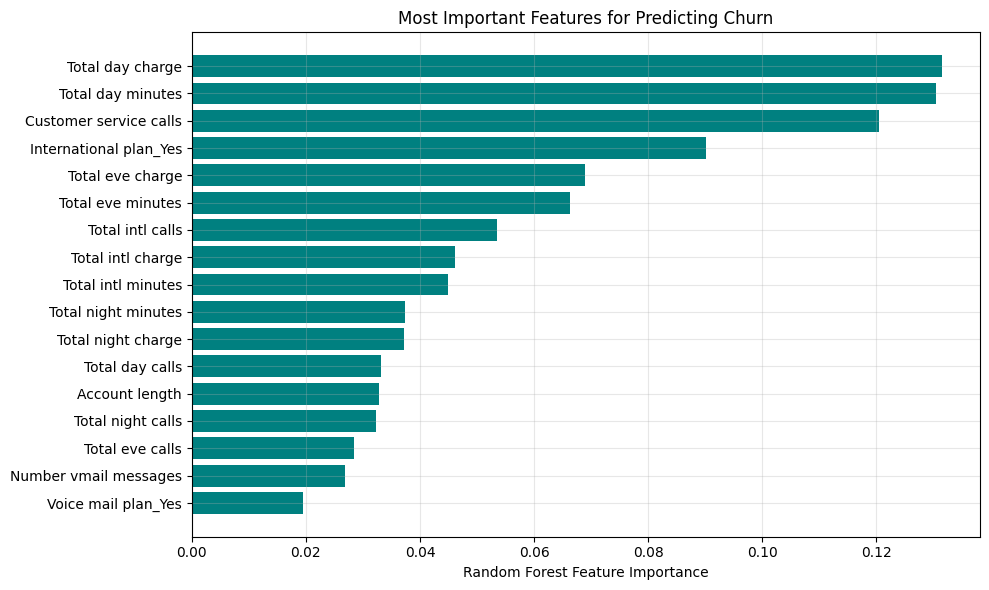

In [28]:
importances = best_rf.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='teal')
plt.xlabel('Random Forest Feature Importance')
plt.title('Most Important Features for Predicting Churn')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()